# code_135 · Native Fourier layers and resolution transfer

**Book:** section 26.3. A self-contained operator-learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_26_GUIDE.md), [run evidence](../CHAPTER_26_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_135).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3135;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3135


<a id="fourier-operator-contract"></a>
 ## Fourier parameters have a declared physical grid and frequency meaning
 Learn one periodic heat step over0.1 on the unit interval with diffusivity0.003. Analytic Fourier decay supplies generated truth. Source128/development32/final64 functions use frequencies1–6 and a random constant;64 further final functions use frequencies10–14. A native three-block Fourier operator lifts one channel to eight, mixes retained rFFT modes0–7 with learned complex matrices, adds local channel maps, applies GELU and projects to one output. Two rates0.003/0.01 receive800 full-batch updates each, with development checkpoints every40updates on32-point grids. Frozen weights evaluate the same final functions at32/64/128 points. Both input and output are resampled from the same analytic function definitions; no target refitting occurs. This reference assumes periodic boundaries.


,points,cohort,field_MSE,relative_L2,mean_mass_absolute_error
0,32,Source-frequency final,0.000134,0.008405,0.002835
1,32,High-frequency final,0.008807,0.404035,0.021277
2,64,Source-frequency final,0.000130,0.008291,0.002780
3,64,High-frequency final,0.008718,0.401984,0.021576
4,128,Source-frequency final,0.000130,0.008285,0.002775
5,128,High-frequency final,0.008727,0.402174,0.021562


Selected: (0.01, 800)


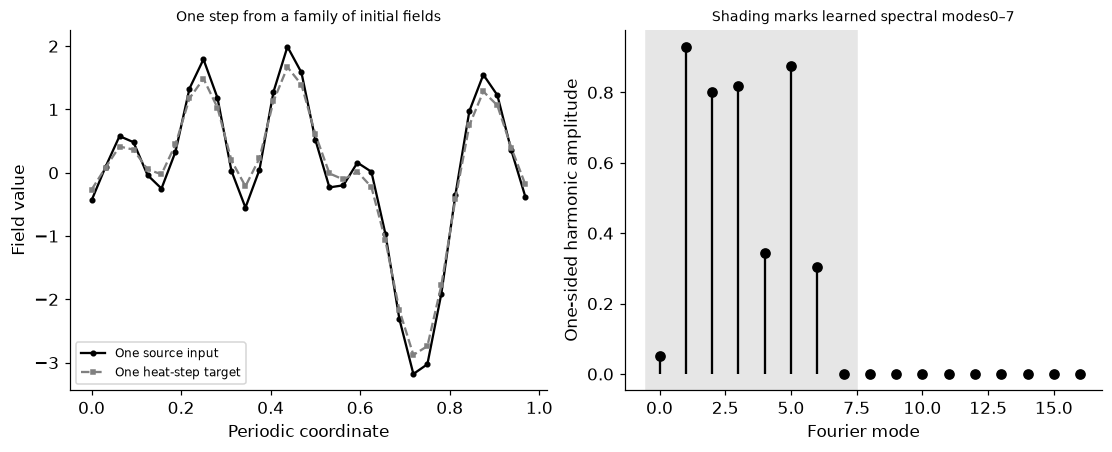

In [2]:
import copy
N=32;nu=.003;delta=.1;low_coeff=rng.normal(size=(224,13));low_coeff[:,0]*=.2;low_coeff[:,1:]/=np.sqrt(np.repeat(np.arange(1,7),2));high_coeff=np.zeros((64,29));high_coeff[:,0]=rng.normal(0,.2,64);high_coeff[:,19:]=rng.normal(size=(64,10))/np.sqrt(np.repeat(np.arange(10,15),2))
def field(coeff,n,advance=False):
    x=np.arange(n)/n;m=(coeff.shape[1]-1)//2;result=np.repeat(coeff[:,:1],n,axis=1)
    for k in range(1,m+1):
        decay=np.exp(-nu*(2*np.pi*k)**2*delta) if advance else 1.;result+=decay*(coeff[:,2*k-1,None]*np.cos(2*np.pi*k*x)+coeff[:,2*k,None]*np.sin(2*np.pi*k*x))
    return result
class Spectral(nn.Module):
    def __init__(self,width=8,modes=8):super().__init__();self.modes=modes;self.weights=nn.Parameter(torch.randn(width,width,modes,2)*.05)
    def forward(self,x):
        spectrum=torch.fft.rfft(x,dim=-1,norm='forward');out=torch.zeros_like(spectrum);out[:,:,:self.modes]=torch.einsum('bim,iom->bom',spectrum[:,:,:self.modes],torch.view_as_complex(self.weights));return torch.fft.irfft(out,n=x.shape[-1],dim=-1,norm='forward')
class FourierOperator(nn.Module):
    def __init__(self):super().__init__();self.lift=nn.Conv1d(1,8,1);self.spectral=nn.ModuleList([Spectral() for _ in range(3)]);self.local=nn.ModuleList([nn.Conv1d(8,8,1) for _ in range(3)]);self.project=nn.Sequential(nn.Conv1d(8,16,1),nn.GELU(),nn.Conv1d(16,1,1))
    def forward(self,x):
        h=self.lift(x[:,None,:])
        for spectral,local in zip(self.spectral,self.local):h=torch.nn.functional.gelu(spectral(h)+local(h))
        return self.project(h)[:,0,:]
source=field(low_coeff[:128],32);output=field(low_coeff[:128],32,True);scale=float(output.std());X=torch.tensor(source);Y=torch.tensor(output);DX=torch.tensor(field(low_coeff[128:160],32));DY=torch.tensor(field(low_coeff[128:160],32,True));candidates=[];family_best=np.inf
for rate in [.003,.01]:
    torch.manual_seed(SEED);model=FourierOperator();opt=torch.optim.Adam(model.parameters(),lr=rate);best=np.inf
    for step in range(1,801):
        opt.zero_grad();loss=((model(X)-Y)/scale).square().mean();loss.backward();opt.step()
        if step%40==0:
            with torch.no_grad():score=float((model(DX)-DY).square().mean())
            if score<best:best=score;state=copy.deepcopy(model.state_dict());best_step=step
    candidates.append({'learning_rate':rate,'best_update':best_step,'development_MSE':best})
    if best<family_best:family_best=best;selected=(rate,best_step,state)
rate,best_step,state=selected;model.load_state_dict(state);model.eval();rows=[]
for n in [32,64,128]:
    for name,coeff in [('Source-frequency final',low_coeff[160:]),('High-frequency final',high_coeff)]:
        inp=field(coeff,n);truth=field(coeff,n,True)
        with torch.no_grad():pred=model(torch.tensor(inp)).numpy()
        rows.append({'points':n,'cohort':name,'field_MSE':float(np.mean((pred-truth)**2)),'relative_L2':float(np.linalg.norm(pred-truth)/np.linalg.norm(truth)),'mean_mass_absolute_error':float(np.mean(np.abs(pred.mean(1)-truth.mean(1))))})
# Verify the spectral calculation on included modes independently of fitted performance.
identity=Spectral(1,8)
with torch.no_grad():identity.weights.zero_();identity.weights[0,0,:,0]=1
for n in [32,64,128]:
    sine=torch.sin(2*torch.pi*3*torch.arange(n)/n)[None,None,:];torch.testing.assert_close(identity(sine),sine,atol=1e-14,rtol=1e-12);probe=1+torch.cos(torch.pi*torch.arange(n));torch.testing.assert_close(torch.fft.irfft(torch.fft.rfft(probe,norm='forward'),n=n,norm='forward'),probe,atol=1e-14,rtol=1e-12)
def squared_spectrum(n):return np.abs(np.fft.rfft(np.cos(2*np.pi*12*np.arange(n)/n)**2,norm='forward'))
def amplitude_spectrum(n):
    amplitudes=2*squared_spectrum(n);amplitudes[[0,-1]]*=.5;return amplitudes
coarse_alias=2*squared_spectrum(32)[8];fine_alias=2*squared_spectrum(128)[8];assert abs(coarse_alias-.5)<1e-12 and fine_alias<1e-12
RESULTS.update(comparisons=rows,candidates=candidates,selected_rate=rate,best_update=best_step,real_scalar_parameters=sum(p.numel() for p in model.parameters()),case_counts=[128,32,64,64],training_grid=32,evaluation_grids=[32,64,128],retained_modes=list(range(8)),diffusivity=nu,step=delta,FFT_normalization='forward for transform and inverse',quadratic_alias_amplitude_at_mode8={'32_point_grid':float(coarse_alias),'128_point_grid':float(fine_alias)});display(pd.DataFrame(rows));print('Selected:',selected[:2])
fig,axes=plt.subplots(1,2,figsize=(10,4));xx=np.arange(32)/32;axes[0].plot(xx,source[0],'ko-',markersize=3,label='One source input');axes[0].plot(xx,output[0],'s--',color='.5',markersize=3,label='One heat-step target');axes[0].set(xlabel='Periodic coordinate',ylabel='Field value',title='One step from a family of initial fields');axes[0].legend(fontsize=8);spectrum=2*np.abs(np.fft.rfft(source[0],norm='forward'));spectrum[[0,-1]]*=.5;axes[1].stem(np.arange(len(spectrum)),spectrum,linefmt='k-',markerfmt='ko',basefmt=' ');axes[1].axvspan(-.5,7.5,color='.9',zorder=-2);axes[1].set(xlabel='Fourier mode',ylabel='One-sided harmonic amplitude',title='Shading marks learned spectral modes0–7');plt.show()


<a id="fourier-transfer-limits"></a>
 ## A reusable spectral matrix does not guarantee reusable accuracy
 Retained-mode matrices do not depend on the number of uniform grid points, but the input sampling, nonlinearity, normalization and available modes still affect the computed function. The local path and nonlinear activation can pass or generate frequencies beyond the retained spectral block. The alias fixture squares a mode12 cosine: its mode24 component appears as mode8 on32 samples and is distinct on128 samples. This is an independent nonlinear sampling demonstration, not a measured decomposition of the trained operator's error. DC and Nyquist transform round trips are checked separately; imaginary coefficients at real-only frequencies do not add identifiable output degrees of freedom. Parameter counts include stored real/imaginary coefficients. Nonperiodic domains need an explicit boundary representation or adapter, not an unexamined FFT wrap.


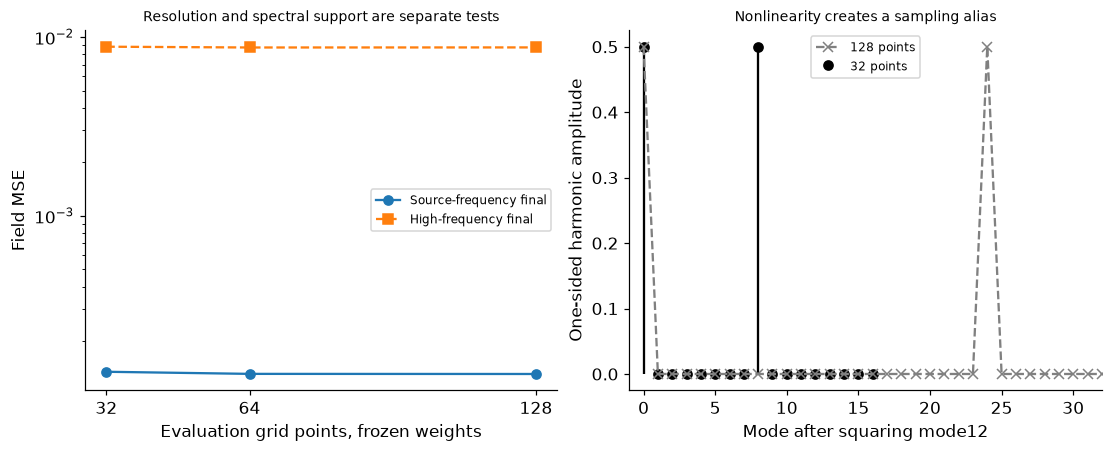

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4))
for name,style in [('Source-frequency final','o-'),('High-frequency final','s--')]:
    subset=[r for r in rows if r['cohort']==name];axes[0].plot([r['points'] for r in subset],[r['field_MSE'] for r in subset],style,label=name)
axes[0].set(yscale='log',xticks=[32,64,128],xlabel='Evaluation grid points, frozen weights',ylabel='Field MSE',title='Resolution and spectral support are separate tests');axes[0].legend(fontsize=8);axes[1].stem(np.arange(17),amplitude_spectrum(32),linefmt='k-',markerfmt='ko',basefmt=' ',label='32 points');axes[1].plot(np.arange(33),amplitude_spectrum(128)[:33],'x--',color='.5',label='128 points');axes[1].set(xlim=(-1,32),xlabel='Mode after squaring mode12',ylabel='One-sided harmonic amplitude',title='Nonlinearity creates a sampling alias');axes[1].legend(fontsize=8);plt.show()
assert len(rows)==6 and all(np.isfinite(r['field_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_135','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual native complex spectral convolution', 'lifting local paths and projection', 'same-function grid transfer without refitting', 'retained-mode and FFT identity checks', 'nonlinear aliasing and changed spectral support'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual native complex spectral convolution", "lifting local paths and projection", "same-function grid transfer without refitting", "retained-mode and FFT identity checks", "nonlinear aliasing and changed spectral support"], "elapsed_seconds": 7.605, "example_id": "code_135", "hardware": "Darwin arm64 CPU", "results": {"FFT_normalization": "forward for transform and inverse", "best_update": 800, "candidates": [{"best_update": 800, "development_MSE": 0.0006177733106658945, "learning_rate": 0.003}, {"best_update": 800, "development_MSE": 0.0003035280224026267, "learning_rate": 0.01}], "case_counts": [128, 32, 64, 64], "comparisons": [{"cohort": "Source-frequency final", "field_MSE": 0.00013378117994685857, "mean_mass_absolute_error": 0.0028349612505254645, "points": 32, "relative_L2": 0.008404700256117814}, {"cohort": "High-frequency final", "field_MSE": 0.008807498553916392, "mean_mass_absolute_error": 0.021277495145605674, "points": 32